In [1]:
#follow Dr Kwon codes


In [1]:
import glob
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
import seaborn as sns
import re
from Bio import SeqIO
from collections import Counter
import os

!pip install biopython
!pip install XlsxWriter

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [5]:
# Change the direction below to the fasta file of your bowtie index, in this case EGFP.fa or something like that

# ===================================================================================
sBowtieFasta = '/home/ykjli/genome/EGFP/EGFP.fa' 
# ===================================================================================

for record in SeqIO.parse(open(sBowtieFasta, 'r'), 'fasta'):
    sName = str(record.id)
    sSeq = str(record.seq)
    if sName == 'EGFP-C1':
        sRefSeq = sSeq

In [6]:
dTargetGene = {'EGFP-C1':'EGFP-C1'}
nTarget2Pos = 326
#The 3'end of crEGFP7

In [ ]:
# Change the direction below to your .simple.txt files

# ===================================================================================
lSamFiles = glob.glob('/home/ykjli/project/20260724_novaseq112_analysis/data/*.bt2output.simple.txt')
sMatchFilter = '50M' 
# ===================================================================================

lSamDf = []
for sSamFile in lSamFiles:
    print(sSamFile)
    
    sFileName = sSamFile.split('/')[-1].split('.bt2output')[0]        
    sName = sFileName.split('.')[0]
    #sTargetGeneName = dTargetGene[ sName.split('-')[-1] ]
    sTargetGeneName = dTargetGene['EGFP-C1']
    
    df = pd.read_table(sSamFile, header=None, sep=' ', names=['ReadNameCollapsed', 'Gene', 'Pos', 'MatchInfo', 'Seq'])                
    df['SampleName'] = sName
    df['SortedReadOrder'] = df.apply(lambda row: str(row['ReadNameCollapsed'].split('-')[0]), axis=1)
    df['CollapsedReadCount'] = df.apply(lambda row: int(row['ReadNameCollapsed'].split('-')[1]), axis=1)

    #df['TargetPos'] = df.apply(lambda row: dTarget2Pos[ row['SampleName'] ], axis=1)
    df['TargetPos'] = df.apply(lambda row: nTarget2Pos, axis=1)
    
    print('--')
    print(sName)
    print('all row numbers: ', len(df))
    print('all row read counts: ', df['CollapsedReadCount'].sum())
    
    df = df[df['Gene'] == sTargetGeneName]
    print('row numbers after selecting target genes: ', len(df))
    print('row read counts after selecting target genes: ', df['CollapsedReadCount'].sum())

    print('row numbers after selecting a match filter: ', len(df))
    print('row read counts after selecting a match filter: ', df['CollapsedReadCount'].sum())

# Get the nearby sequence around the cleavage site
    df['aroundClvSite'] = df['Pos'].apply(lambda pos: sRefSeq[pos-5: pos+3])
    df['3ntMotif']      = df['Pos'].apply(lambda pos: sRefSeq[pos-3: pos])

    df['distance']      = df['Pos'] - df['TargetPos']

# Best way to avoid type errors:
    df['MotifDist'] = df['3ntMotif'].astype(str) + ', ' + \
    df['distance'].astype(str) + 'nt'
    
    lSamDf.append((sName, df))
    

/home/ykjli/project/20260707_novaseq110_analysis/data/17-Psp-T136R.bt2output.simple.txt
--
17-Psp-T136R
all row numbers:  31610
all row read counts:  3875284
row numbers after selecting target genes:  314
row read counts after selecting target genes:  3685753
row numbers after selecting a match filter:  314
row read counts after selecting a match filter:  3685753
/home/ykjli/project/20260707_novaseq110_analysis/data/10-Psp-T136I.bt2output.simple.txt
--
10-Psp-T136I
all row numbers:  31445
all row read counts:  3435835
row numbers after selecting target genes:  265
row read counts after selecting target genes:  3122936
row numbers after selecting a match filter:  265
row read counts after selecting a match filter:  3122936
/home/ykjli/project/20260707_novaseq110_analysis/data/4-Psp-T136C.bt2output.simple.txt
--
4-Psp-T136C
all row numbers:  25826
all row read counts:  3131076
row numbers after selecting target genes:  290
row read counts after selecting target genes:  2888478
row number

In [16]:
# This block is for me to sort the samples in natural numerical order

def natural_sort_key(s):
    """Sorts strings containing numbers in human/natural order."""
    def convert(text):
        return int(text) if text.isdigit() else text.lower()
    return [convert(c) for c in re.split('([0-9]+)', s)]

lSamDfSorted = sorted(lSamDf)
lSamDfSorted = sorted(lSamDfSorted, key=lambda x: natural_sort_key(x[0]))  # x[0] is sName

## Run the next block to get piecharts!

1-Psp-WT-NT
335269
2-Psp-WT-EGFP7
1543417
3-Psp-T136A
2594929
4-Psp-T136C
2467065
5-Psp-T136D
4169388
6-Psp-T136E
5271030
7-Psp-T136F
1347251
8-Psp-T136G
3242096
9-Psp-T136H
1465340
10-Psp-T136I
2507724
11-Psp-T136K
1949395
12-Psp-T136L
1530198
13-Psp-T136M
3915678
14-Psp-T136N
2009873
15-Psp-T136P
2644093
16-Psp-T136Q
2948448
17-Psp-T136R
2835032
18-Psp-T136S
1843320
19-Psp-T136V
3132293
20-Psp-T136W
4884406
21-Psp-T136Y
2977764


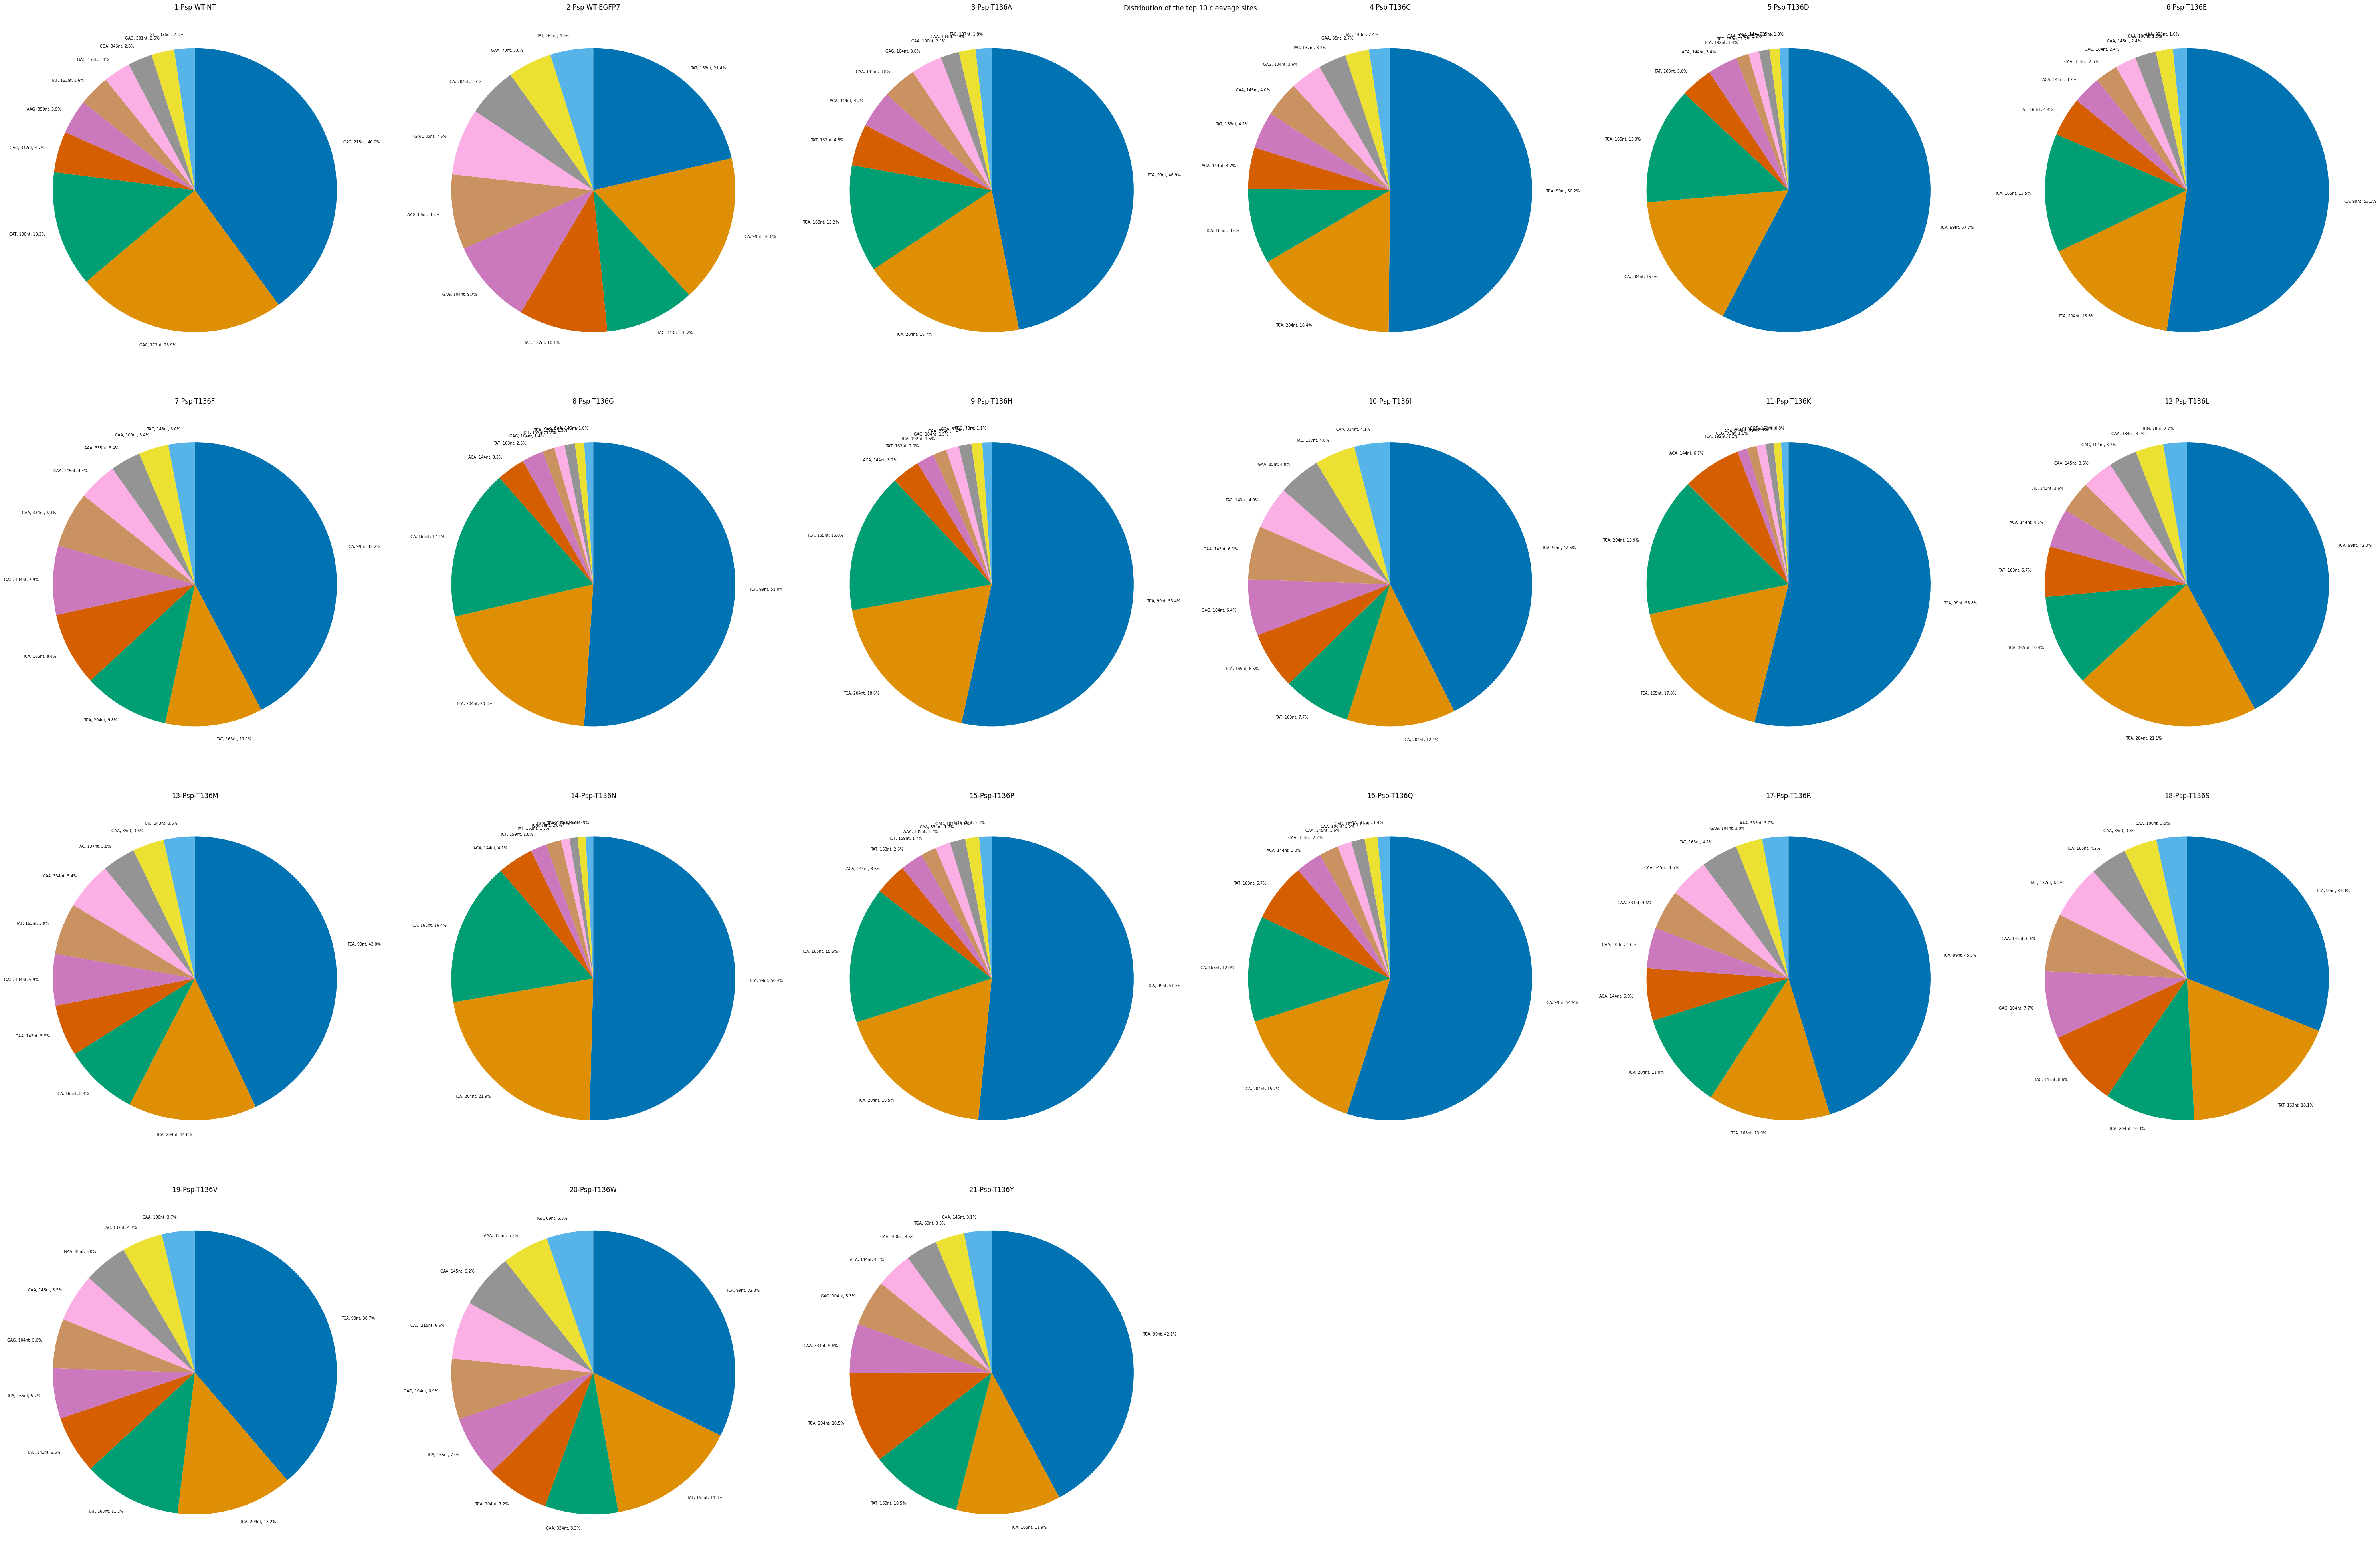

In [ ]:
# Normalized by the sum of counts
fRatioForTopSeq = 0.1

# Change the direction below to where you want to store the piechart data

# ===================================================================================
sWorkDir = '/home/ykjli/project/20260724_novaseq112_analysis/'
# ===================================================================================

nMultiplyFactor = 1000
nPieQuery = 10 # Visualize only top 10 

fig = plt.figure(figsize=(60, 40))
colors = sns.color_palette("colorblind")   
nSubX = 4
nSubY = 6
nSubOrder = 0 # a subplot order

for sName, dfSam in lSamDfSorted:
    nSubOrder += 1
    print(sName)

    dfSamSorted = dfSam.sort_values(by='CollapsedReadCount', ascending=False)

    nTopRatio = int(len(dfSamSorted) * fRatioForTopSeq)
    dfSamTop = dfSamSorted.iloc[:nTopRatio,]

    nSumCount = dfSamTop['CollapsedReadCount'].sum()
    print(nSumCount)
    
    # Check dinucleotides
    lTopSeq = []        
    for sSeq, nCount in zip( dfSamTop['aroundClvSite'].tolist(), dfSamTop['CollapsedReadCount'].tolist() ):
        lTopSeq.append([sSeq, nCount])
    #print(lTopSeq[:4])
    
    # pie chart ---------------------------
        
    ax1 = fig.add_subplot(nSubX, nSubY, nSubOrder)
    ax1.set_title(sName)    
    
    _wedges, labels, percentages = ax1.pie(dfSamTop['CollapsedReadCount'][:nPieQuery], 
                                           labels=dfSamTop['MotifDist'][:nPieQuery], 
                                           autopct='%1.1f%%', 
                                           colors=colors,                                           
                                           startangle=90,
                                           counterclock=False) 
                                           #radius=0.5)
    
    for label, percentage in zip(labels, percentages):
        label.set_text(label.get_text() + ', ' + percentage.get_text())
        label.set_fontsize(7)
        percentage.remove()

    
    ### ------
    sClvName = sName + '_weighted'
    # Make an input file for MEME
    sMemeInputFile = sWorkDir + '{}_plogo_input_v2.txt'.format(sClvName)    
    
    with open(sMemeInputFile, 'w') as f:
        for n, (sSeq, nCount) in enumerate(lTopSeq):
            for k in range(int(nCount / nSumCount * nMultiplyFactor)):
                f.write('>' + str(n) + '\n')
                f.write(sSeq + '\n')
        
    # Save a table
    dfSamTop.to_csv(sWorkDir + '{}_mapped_v3.txt'.format(sClvName), sep='\t', index=False)
    
plt.suptitle('Distribution of the top 10 cleavage sites')
plt.tight_layout()
plt.savefig(sWorkDir + 'pie_top10_260708.png')
plt.show()
plt.close()

## Run the next block to get barcharts!

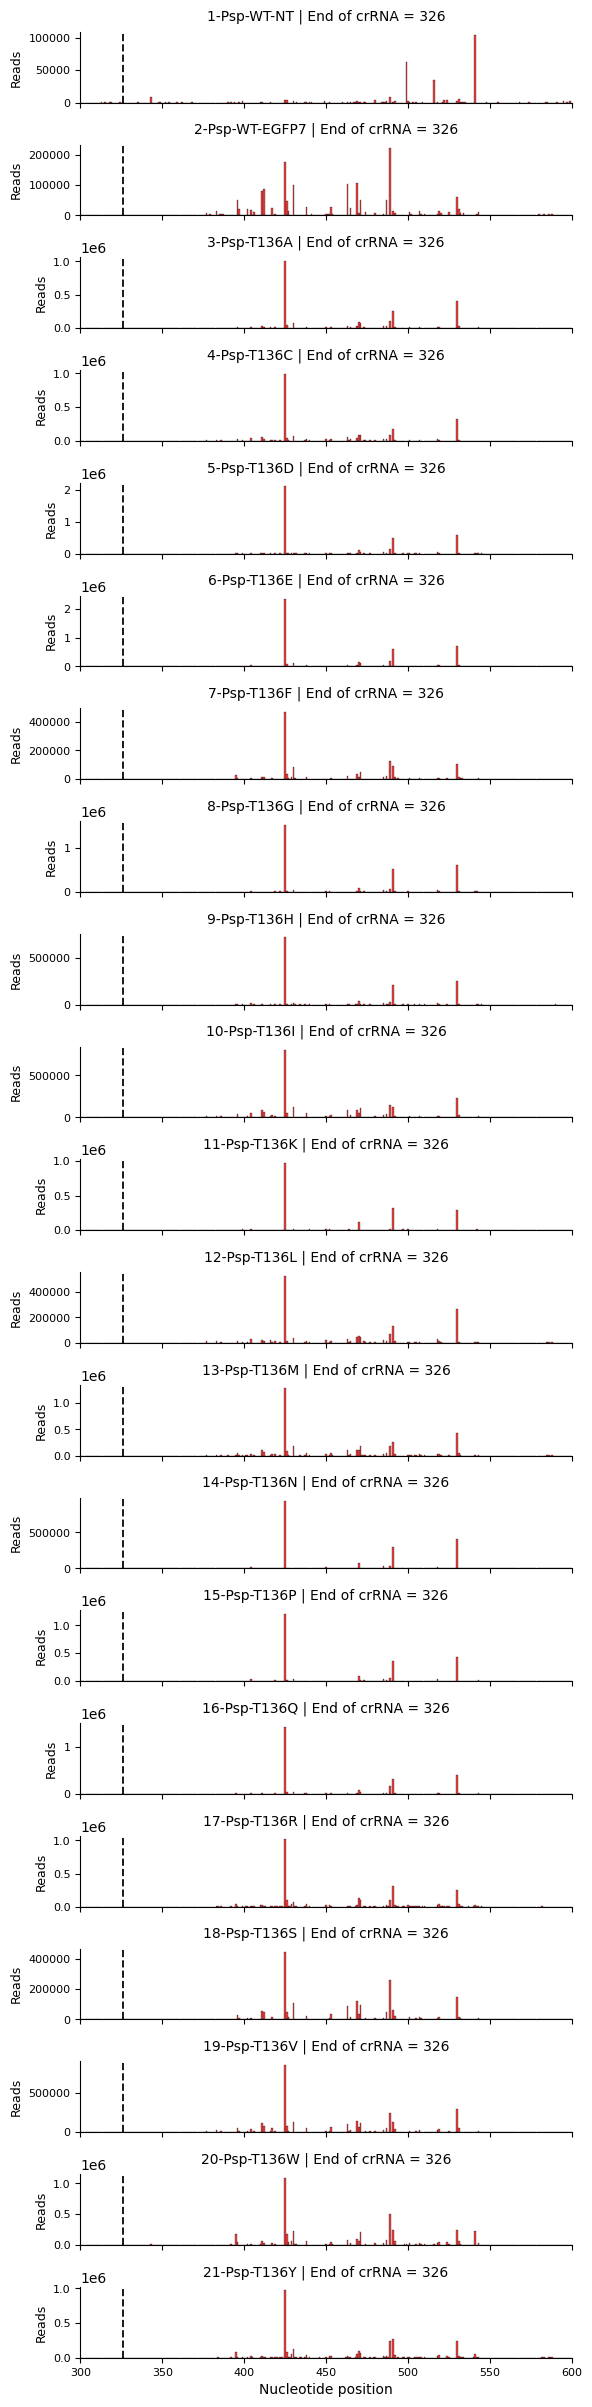

In [ ]:
# Count how many samples you have
n_samples = len(lSamDfSorted)

# Create ONE big figure with n_samples rows and 1 column
fig, axes = plt.subplots(n_samples, 1, figsize=(6, 1.15 * n_samples),  # height scales with number of samples
                         sharex=True)                              # all share the same x-axis (optional but nice)

# If only one sample, axes is not a list → make it always iterable
if n_samples == 1:
    axes = [axes]

for ax, (sName, dfSam) in zip(axes, lSamDfSorted):
    # ——— Count reads per position ———
    counts_by_pos = (dfSam.groupby('Pos')['CollapsedReadCount']
                         .sum()
                         .astype(int))

    nTargetPos = int(dfSam['TargetPos'].iloc[0])

    # ——— Critical fix: create complete consecutive axis from min to max ———
    pos_min = counts_by_pos.index.min()
    pos_max = counts_by_pos.index.max()
    all_positions = np.arange(pos_min, pos_max + 1)                  # every single position
    counts_filled = counts_by_pos.reindex(all_positions, fill_value=0).values

    # ——— Now plot ———
    ax.bar(all_positions, counts_filled,
           width=0.98,                  # almost 1 → bars nearly touch
           color='#ee4444',
           edgecolor='black',
           linewidth=0.2,
           align='center')              # important!

    # ——— Aesthetics (same as before) ———
    ax.set_title(f'{sName} | End of crRNA = {nTargetPos}', fontsize=10, pad=8)
    ax.set_ylabel('Reads', fontsize=9)
    ax.axvline(nTargetPos, color='black', linestyle='--', linewidth=1.4, alpha=0.9)

    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=8)
    ax.set_ylim(0, None)
    ax.set_xlim(300, 600)

# Shared x-axis
axes[-1].set_xlabel('Nucleotide position', fontsize=10)
for ax in axes:
    ax.set_xlim(300, 600)

plt.tight_layout(pad=1.0)   # pad=1.0 gives a bit more breathing room between rows
plt.savefig("260724_clvbar_clean_v3.svg", dpi=600, bbox_inches='tight')
plt.show()

## Run the next block to get excel file!

In [ ]:
# Write an Excel file

sExcelOutputFile = '/home/ykjli/project/20260724_novaseq112_analysis/260724_Jason_novaseq112.xlsx'

lSubset = ['SampleName', 'Gene', 'Seq', 'CollapsedReadCount', 'SortedReadOrder', 'TargetPos', 'distance', 'aroundClvSite', '3ntMotif']
 
with pd.ExcelWriter(sExcelOutputFile, engine='xlsxwriter') as writer:            

    for sName, dfSam in lSamDfSorted:           

        dfSam = dfSam[lSubset]

        dfSam['SortedReadOrder'] = dfSam['SortedReadOrder'].astype(int)

        dfSam = dfSam.sort_values(by='SortedReadOrder', ascending=True)

        dfSam.to_excel(writer, sheet_name=sName, index=False)


/tmp/ipykernel_2112942/3528531920.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfSam['SortedReadOrder'] = dfSam['SortedReadOrder'].astype(int)
/tmp/ipykernel_2112942/3528531920.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfSam['SortedReadOrder'] = dfSam['SortedReadOrder'].astype(int)
/tmp/ipykernel_2112942/3528531920.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in t